# Optiver Trading at the Close: Forecasting Closing Auction Price Moves

**Author:** Steven Ghabyous | Master of Financial Mathematics, NC State University

## Problem

In the last ten minutes of each trading day, Nasdaq runs a closing auction where buy and sell interest is matched to set the official closing price. Kaggle's *Optiver Trading at the Close* dataset contains order book and auction data for about 200 stocks over 481 trading days. The target is the stock's move over the next 60 seconds relative to a synthetic index, measured in basis points.

This is an independent project completed after the competition closed.

## Approach

1. Engineer order book features: bid-ask spread, imbalance ratio, and order flow
2. Validate **out of time**: train on earlier trading days and test on later ones, so the model never sees the future
3. Compare a LightGBM regressor against a naive baseline that always predicts zero

> **Note on validation.** An earlier version of this notebook used a random train/validation split. With time series data, that lets rows from the same trading day appear in both sets, so the model is partly tested on days it has already seen and the error looks better than it really is. That version also used `date_id` and `time_id` as features, and `date_id` ranked among the most important features, a clear sign of leakage. This version fixes both issues.

---
# 1. Load the data

Run on Kaggle with the competition data attached.

In [1]:
import numpy as np
import pandas as pd
import lightgbm as lgb
import matplotlib.pyplot as plt
from sklearn.metrics import mean_absolute_error

train_df = pd.read_csv('/kaggle/input/optiver-trading-at-the-close/train.csv')
print(train_df.shape)
print("Trading days:", train_df['date_id'].nunique(), "| Stocks:", train_df['stock_id'].nunique())
train_df.head()

(5237980, 17)
Trading days: 481 | Stocks: 200


,stock_id,date_id,seconds_in_bucket,imbalance_size,imbalance_buy_sell_flag,reference_price,matched_size,far_price,near_price,bid_price,bid_size,ask_price,ask_size,wap,target,time_id,row_id
0,0,0,0,3180602.69,1,0.999812,13380276.64,NaN,NaN,0.999812,60651.50,1.000026,8493.03,1.0,-3.029704,0,0_0_0
1,1,0,0,166603.91,-1,0.999896,1642214.25,NaN,NaN,0.999896,3233.04,1.000660,20605.09,1.0,-5.519986,0,0_0_1
2,2,0,0,302879.87,-1,0.999561,1819368.03,NaN,NaN,0.999403,37956.00,1.000298,18995.00,1.0,-8.389950,0,0_0_2
3,3,0,0,11917682.27,-1,1.000171,18389745.62,NaN,NaN,0.999999,2324.90,1.000214,479032.40,1.0,-4.010200,0,0_0_3
4,4,0,0,447549.96,-1,0.999532,17860614.95,NaN,NaN,0.999394,16485.54,1.000016,434.10,1.0,-7.349849,0,0_0_4


Rows with a missing target cannot be used for training or evaluation, so they are dropped.

In [2]:
train_df = train_df.dropna(subset=['target']).reset_index(drop=True)
print(train_df.shape)
print(train_df['target'].describe())

(5237892, 17)
count    5.237892e+06
mean    -4.756125e-02
std      9.452860e+00
min     -3.852898e+02
25%     -4.559755e+00
50%     -6.020069e-02
75%      4.409552e+00
max      4.460704e+02
Name: target, dtype: float64


---
# 2. Feature engineering

- **Spread** (`ask_price - bid_price`): a measure of liquidity and uncertainty
- **Imbalance ratio** (`imbalance_size / (bid_size + ask_size)`): auction imbalance relative to resting liquidity
- **Order flow** (`bid_size - ask_size`): net buying versus selling pressure at the top of the book

Missing values are left as NaN, since LightGBM handles them natively. Filling `far_price` and `near_price` with 0 would be misleading, because a price of 0 is not a real value. Division by zero in the imbalance ratio is set to NaN.

In [3]:
def add_features(df):
    df = df.copy()
    df['spread'] = df['ask_price'] - df['bid_price']
    df['imbalance_ratio'] = df['imbalance_size'] / (df['bid_size'] + df['ask_size'])
    df['order_flow'] = df['bid_size'] - df['ask_size']
    df['imbalance_ratio'] = df['imbalance_ratio'].replace([np.inf, -np.inf], np.nan)
    return df

train_df = add_features(train_df)
train_df[['stock_id', 'date_id', 'seconds_in_bucket', 'spread', 'imbalance_ratio', 'order_flow']].head()

,stock_id,date_id,seconds_in_bucket,spread,imbalance_ratio,order_flow
0,0,0,0,0.000214,45.999339,52158.47
1,1,0,0,0.000764,6.988967,-17372.05
2,2,0,0,0.000895,5.318254,18961.00
3,3,0,0,0.000215,24.758495,-476707.50
4,4,0,0,0.000622,26.451506,16051.44


---
# 3. Out-of-time split: train, early stopping, and test

The data is split by trading day into three consecutive blocks:

- **Train:** the first 70% of days
- **Early stopping:** the next 10% of days, used only to decide how many trees to build
- **Test:** the last 20% of days, touched only once for the final score

Keeping the test days separate from the early-stopping days matters: if the same days were used to pick the number of trees and to report the score, the score would be slightly optimistic.

Identifier columns are excluded from the features. `date_id` and `time_id` only count days and time steps, so they carry no economic information and would let the model memorize specific days. `row_id` is a string label. `stock_id` and `seconds_in_bucket` are kept, since the same stocks appear in the future and time within the auction is genuinely informative.

In [4]:
days = np.sort(train_df['date_id'].unique())
train_end = days[int(len(days) * 0.7) - 1]
es_end = days[int(len(days) * 0.8) - 1]

train_mask = train_df['date_id'] <= train_end
es_mask = (train_df['date_id'] > train_end) & (train_df['date_id'] <= es_end)
test_mask = train_df['date_id'] > es_end

drop_cols = ['target', 'row_id', 'date_id', 'time_id']
features = [c for c in train_df.columns if c not in drop_cols]

X_train, y_train = train_df.loc[train_mask, features], train_df.loc[train_mask, 'target']
X_es, y_es = train_df.loc[es_mask, features], train_df.loc[es_mask, 'target']
X_test, y_test = train_df.loc[test_mask, features], train_df.loc[test_mask, 'target']

print(f"Train days 0-{train_end} | Early stopping days {train_end+1}-{es_end} | Test days {es_end+1}-{days.max()}")
print("Train:", X_train.shape, "| Early stopping:", X_es.shape, "| Test:", X_test.shape)
print("Features:", features)

Train days 0-335 | Early stopping days 336-383 | Test days 384-480
Train: (3642948, 16) | Early stopping: (528000, 16) | Test: (1066944, 16)
Features: ['stock_id', 'seconds_in_bucket', 'imbalance_size', 'imbalance_buy_sell_flag', 'reference_price', 'matched_size', 'far_price', 'near_price', 'bid_price', 'bid_size', 'ask_price', 'ask_size', 'wap', 'spread', 'imbalance_ratio', 'order_flow']


---
# 4. Baseline

The target is noisy and centered near zero, so a model that always predicts 0 is a meaningful benchmark. Any real model needs to beat it.

In [5]:
baseline_mae = mean_absolute_error(y_test, np.zeros(len(y_test)))
print(f"Baseline MAE on test days (always predict 0): {baseline_mae:.4f} bps")

Baseline MAE on test days (always predict 0): 6.0618 bps


---
# 5. LightGBM model

The model is trained with an MAE objective, since the competition was scored on mean absolute error. Early stopping on the separate early-stopping days picks the number of trees.

In [6]:
model = lgb.LGBMRegressor(
    objective='mae',
    n_estimators=2000,
    learning_rate=0.05,
    num_leaves=64,
    random_state=42,
    verbose=-1
)

model.fit(
    X_train, y_train,
    eval_set=[(X_es, y_es)],
    eval_metric='mae',
    callbacks=[lgb.early_stopping(stopping_rounds=100), lgb.log_evaluation(100)]
)

Training until validation scores don't improve for 100 rounds


[100]	valid_0's l1: 6.29989


[200]	valid_0's l1: 6.2946


[300]	valid_0's l1: 6.29025


[400]	valid_0's l1: 6.2883


[500]	valid_0's l1: 6.28723


[600]	valid_0's l1: 6.28626


[700]	valid_0's l1: 6.2859


[800]	valid_0's l1: 6.28585


Early stopping, best iteration is:
[725]	valid_0's l1: 6.28579


,num_leaves,64
,learning_rate,0.05
,n_estimators,2000
,objective,'mae'
,random_state,42
,verbose,-1
,boosting_type,'gbdt'
,max_depth,-1
,subsample_for_bin,200000
,class_weight,None
,min_split_gain,0.0


---
# 6. Results

In [7]:
y_pred = model.predict(X_test)
model_mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(np.mean((y_test - y_pred) ** 2))
improvement = (baseline_mae - model_mae) / baseline_mae

print("Out-of-sample results on the final 20% of trading days")
print(f"Baseline MAE:  {baseline_mae:.4f} bps")
print(f"LightGBM MAE:  {model_mae:.4f} bps")
print(f"LightGBM RMSE: {rmse:.4f} bps")
print(f"Improvement over baseline: {improvement:.2%}")

Out-of-sample results on the final 20% of trading days
Baseline MAE:  6.0618 bps
LightGBM MAE:  5.9707 bps
LightGBM RMSE: 8.8846 bps
Improvement over baseline: 1.50%


## Feature importance (gain)

With identifiers removed, importance reflects real market information rather than the model recognizing specific days.

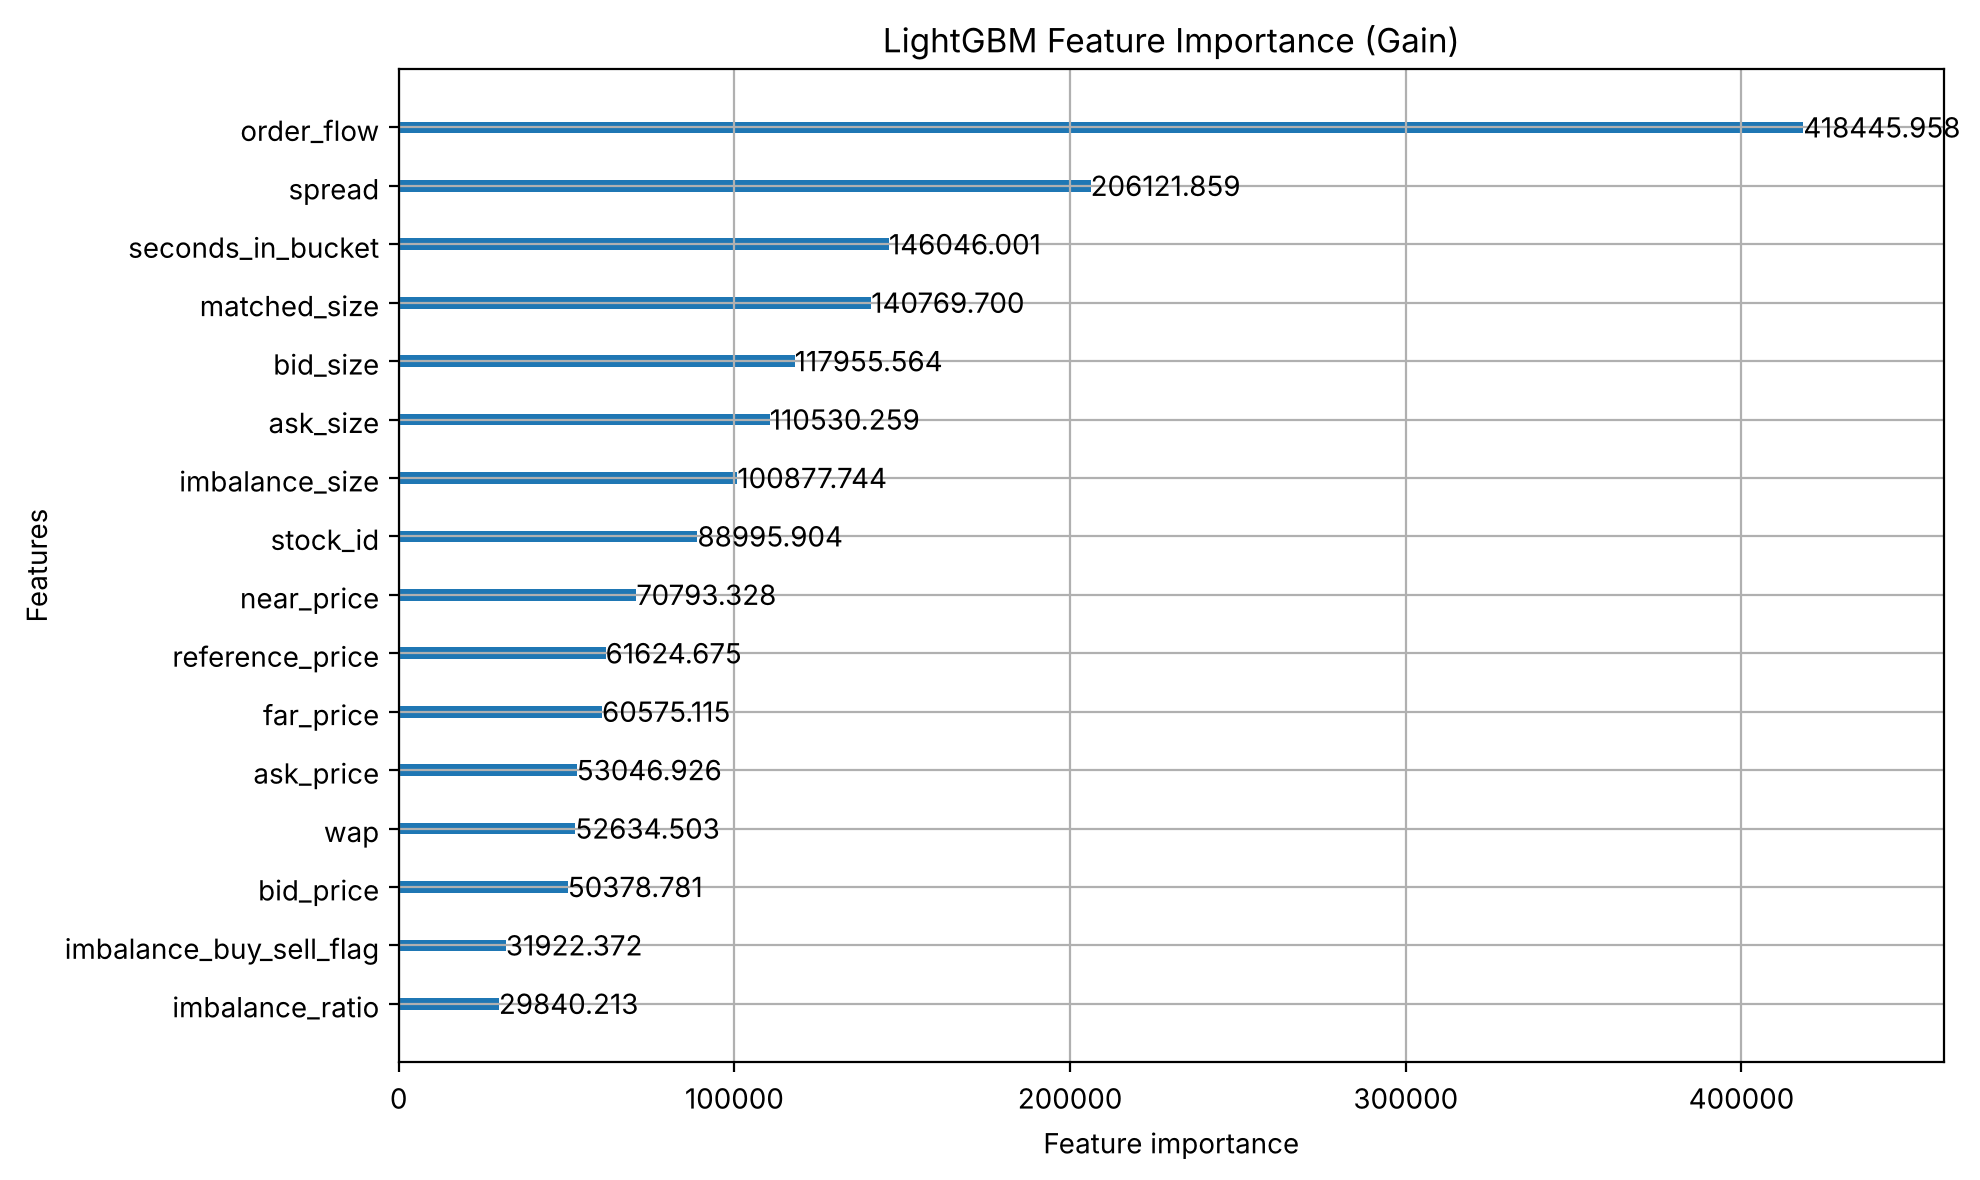

order_flow                 0.240
spread                     0.118
seconds_in_bucket          0.084
matched_size               0.081
bid_size                   0.068
ask_size                   0.064
imbalance_size             0.058
stock_id                   0.051
near_price                 0.041
reference_price            0.035
far_price                  0.035
ask_price                  0.030
wap                        0.030
bid_price                  0.029
imbalance_buy_sell_flag    0.018
imbalance_ratio            0.017
dtype: float64


In [8]:
lgb.plot_importance(model, importance_type='gain', figsize=(10, 6), max_num_features=20)
plt.title('LightGBM Feature Importance (Gain)')
plt.tight_layout()
plt.show()

imp = pd.Series(model.booster_.feature_importance(importance_type='gain'), index=features)
print((imp / imp.sum()).sort_values(ascending=False).round(3))

---
# 7. Conclusion

Short-horizon price moves are close to unpredictable, so the realistic goal is a small but real improvement over the zero baseline on unseen trading days. The improvement reported above is measured out of time, which makes it an honest estimate of how the model would perform going forward.

## Next steps

- Rolling or expanding walk-forward validation across several periods instead of one split
- Features based on changes within the auction (for example, how imbalance and prices move from one snapshot to the next) and on behavior relative to other stocks at the same time
- Hyperparameter tuning on the walk-forward folds